In [1]:
import pyspark
from pyspark.sql.functions import udf, regexp_extract, unbase64, regexp_replace, upper
from pyspark.sql.types import IntegerType, StringType, ArrayType, FloatType
import base64
from io import BytesIO
from PIL import Image
import torch
from torchvision import transforms
import torchvision.transforms.functional as TF
import numpy



START BASIC ETL TO BRONZE LAYER
BRONZE LAYER = LOAD DATA AND MINOR FORMATTING ISSUES

setup spark session

In [2]:
spark = pyspark.sql.SparkSession.builder.appName("MyApp").config("spark.driver.memory", "8g").getOrCreate()

# Print the SparkSession details to verify
print(spark)

bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)
bash: warning: setlocale: LC_ALL: cannot change locale (en_US.UTF-8)
25/04/04 19:21:03 WARN Utils: Your hostname, Grey resolves to a loopback address: 127.0.1.1; using 172.24.242.6 instead (on interface eth0)
25/04/04 19:21:03 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/04/04 19:21:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
25/04/04 19:21:06 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


load csv file, infer datatypes

In [3]:
idmeta_df = spark.read.csv("./idmeta.csv",header=True, inferSchema=True, sep=",")

In [4]:
idfraudmeta_df = spark.read.csv("./idfraudmeta.csv",header=True, inferSchema=True, sep=",")

see data types

In [5]:
idmeta_df.schema

StructType([StructField('id', StringType(), True), StructField('name', StringType(), True), StructField('address', StringType(), True), StructField('birthday', DateType(), True), StructField('gender', StringType(), True), StructField('ethnicity', StringType(), True), StructField('class', StringType(), True), StructField('issue_date', DateType(), True), StructField('expire_date', DateType(), True), StructField('height', StringType(), True), StructField('weight', StringType(), True), StructField('eye_color', StringType(), True), StructField('hair_color', StringType(), True), StructField('is_donor', BooleanType(), True), StructField('is_veteran', BooleanType(), True), StructField('license_number', StringType(), True)])

In [6]:
idmeta_df.show()

+--------------------+-----------------+--------------------+----------+------+---------+-----+----------+-----------+-------+------+---------+----------+--------+----------+--------------+
|                  id|             name|             address|  birthday|gender|ethnicity|class|issue_date|expire_date| height|weight|eye_color|hair_color|is_donor|is_veteran|license_number|
+--------------------+-----------------+--------------------+----------+------+---------+-----+----------+-----------+-------+------+---------+----------+--------+----------+--------------+
|generated.photos_...|      Jack Martin|624 Superstition ...|1993-11-23|     M|    white|    B|2020-05-09| 2025-05-09|5'-10''|142 lb|      BRO|       BRO|   false|     false|     D90236684|
|generated.photos_...|     Sofia Campos|51 La Canada Driv...|1995-07-08|     F|   latino|    D|2022-10-19| 2027-10-19|5'-03''|196 lb|      BRO|       BRO|   false|     false|     D90554937|
|generated.photos_...|      Nakia Wells|243 Yuma R

heaight and weight are kinda useles as is, lets fix those.

In [7]:
def height_to_inches(height_str):
    if height_str is None:
        return None
    else:
        height_str = height_str.replace("'", "")
        height_str = height_str.replace('"', '')
        ft = int(height_str.split("-")[0])
        inches = int(height_str.split("-")[1])
        return ft * 12 + inches

height_to_inches_udf = udf(height_to_inches, IntegerType())


In [8]:
idmeta_df = idmeta_df.withColumn("height_inches", height_to_inches_udf(idmeta_df["height"]))

In [9]:
idfraudmeta_df = idfraudmeta_df.withColumn("height_inches", height_to_inches_udf(idfraudmeta_df["height"]))

In [10]:
#idfraudmeta_df.show()

In [11]:
idmeta_df = idmeta_df.withColumn("weight_lbs",  regexp_extract("weight", r"(\d+)", 1))

In [12]:
idfraudmeta_df = idfraudmeta_df.withColumn("weight_lbs",  regexp_extract("weight", r"(\d+)", 1))

In [13]:
idmeta_df.show()

+--------------------+-----------------+--------------------+----------+------+---------+-----+----------+-----------+-------+------+---------+----------+--------+----------+--------------+-------------+----------+
|                  id|             name|             address|  birthday|gender|ethnicity|class|issue_date|expire_date| height|weight|eye_color|hair_color|is_donor|is_veteran|license_number|height_inches|weight_lbs|
+--------------------+-----------------+--------------------+----------+------+---------+-----+----------+-----------+-------+------+---------+----------+--------+----------+--------------+-------------+----------+
|generated.photos_...|      Jack Martin|624 Superstition ...|1993-11-23|     M|    white|    B|2020-05-09| 2025-05-09|5'-10''|142 lb|      BRO|       BRO|   false|     false|     D90236684|           70|       142|
|generated.photos_...|     Sofia Campos|51 La Canada Driv...|1995-07-08|     F|   latino|    D|2022-10-19| 2027-10-19|5'-03''|196 lb|      B

In [14]:
upper_cols = ['name', 'gender', 'class', 'eye_color', 'hair_color', 'is_donor', 'is_veteran']
for x in upper_cols:
    idmeta_df = idmeta_df.withColumn(x,  upper(idmeta_df[x]))
    idfraudmeta_df = idfraudmeta_df.withColumn(x, upper(idfraudmeta_df[x]))


In [15]:
idmeta_df.show()

+--------------------+-----------------+--------------------+----------+------+---------+-----+----------+-----------+-------+------+---------+----------+--------+----------+--------------+-------------+----------+
|                  id|             name|             address|  birthday|gender|ethnicity|class|issue_date|expire_date| height|weight|eye_color|hair_color|is_donor|is_veteran|license_number|height_inches|weight_lbs|
+--------------------+-----------------+--------------------+----------+------+---------+-----+----------+-----------+-------+------+---------+----------+--------+----------+--------------+-------------+----------+
|generated.photos_...|      JACK MARTIN|624 Superstition ...|1993-11-23|     M|    white|    B|2020-05-09| 2025-05-09|5'-10''|142 lb|      BRO|       BRO|   FALSE|     FALSE|     D90236684|           70|       142|
|generated.photos_...|     SOFIA CAMPOS|51 La Canada Driv...|1995-07-08|     F|   latino|    D|2022-10-19| 2027-10-19|5'-03''|196 lb|      B

In [16]:
cols_to_drop = ["height", "weight"]

In [17]:
idmeta_df = idmeta_df.drop(*cols_to_drop)

In [18]:
idfraudmeta_df = idfraudmeta_df.drop(*cols_to_drop)

In [19]:
#idmeta_df.show()

In [20]:
idmeta_df.write.mode("overwrite").parquet("./bronze/idmeta.parquet")

In [21]:
idfraudmeta_df.write.mode("overwrite").parquet("./bronze/idfraudmeta.parquet")

In [22]:
idimage_df = spark.read.csv("./idimage.csv",header=True, inferSchema=True, sep=",", quote="\"", multiLine=True)

In [23]:
idimage_df.show()

+--------------------+--------------------+
|                name|           imageData|
+--------------------+--------------------+
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated_fake_2_...|/9j/4AAQSkZJRgABA...|
|generated_fake_2_...|/9j/4AAQSkZJRgABA...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|/9j/4AAQSkZJRgABA...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated_fake_2_...|/9j/4AAQSkZJRgABA...|
|generated.photos_...|/9j/4AAQSkZJRgABA...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGgoAAAANS...|
|generated.photos_...|iVBORw0KGg

In [24]:
idimage_df = idimage_df.withColumn('unencoded_base64', unbase64(idimage_df.imageData))

slight tangent to figure out how to viwe the encoded image

In [25]:
idimage_df.limit(1).show()

+--------------------+--------------------+--------------------+
|                name|           imageData|    unencoded_base64|
+--------------------+--------------------+--------------------+
|generated.photos_...|iVBORw0KGgoAAAANS...|[89 50 4E 47 0D 0...|
+--------------------+--------------------+--------------------+



In [26]:
image = idimage_df.limit(1).collect()

In [27]:
image_raw = image[0][2]

In [28]:
image = Image.open(BytesIO(image_raw))

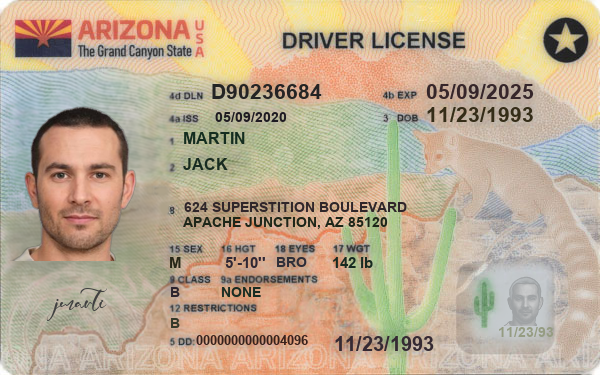

In [29]:
display(image)

In [30]:
img_tensor = TF.to_tensor(image)

In [31]:
img_tensor

tensor([[[1.0000, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
         [1.0000, 1.0000, 1.0000,  ..., 0.9922, 1.0000, 1.0000],
         [0.9961, 0.9961, 0.9922,  ..., 0.9882, 0.9961, 1.0000],
         ...,
         [0.9922, 0.9961, 0.9922,  ..., 0.9961, 0.9961, 1.0000],
         [0.9804, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
         [0.9725, 0.9922, 1.0000,  ..., 0.9961, 0.9922, 0.9922]],

        [[0.9922, 1.0000, 0.9961,  ..., 0.9922, 0.9882, 0.9843],
         [1.0000, 1.0000, 1.0000,  ..., 0.9922, 0.9961, 0.9882],
         [1.0000, 1.0000, 0.9961,  ..., 0.9922, 0.9961, 1.0000],
         ...,
         [0.9882, 0.9922, 0.9922,  ..., 0.9961, 0.9961, 1.0000],
         [0.9804, 1.0000, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
         [0.9725, 0.9922, 1.0000,  ..., 0.9961, 0.9922, 0.9922]],

        [[0.9647, 0.9804, 0.9922,  ..., 1.0000, 1.0000, 1.0000],
         [0.9804, 0.9922, 1.0000,  ..., 1.0000, 1.0000, 1.0000],
         [0.9922, 1.0000, 1.0000,  ..., 1.0000, 0.9882, 0.

wrap the above into udf

In [32]:
def make_tensor(base64_string):
    image = Image.open(BytesIO(base64_string))
    img_tensor = TF.to_tensor(image)
    channel, h, w = img_tensor.shape
    #print(channel, h, w)
    
    img_list = img_tensor.tolist()
    
    return img_list

make_tensor_udf = udf(make_tensor, ArrayType(ArrayType(ArrayType(FloatType()))))

In [33]:
idimage_df = idimage_df.withColumn("img_tensor", make_tensor_udf(idimage_df["unencoded_base64"]))
#idmeta_df = idmeta_df.withColumn("height_inches", height_to_inches_udf(idmeta_df["height"]))

In [34]:
idimage_df.show(1)

3 375 600:>                                                         (0 + 1) / 1]
3 375 600


+--------------------+--------------------+--------------------+--------------------+
|                name|           imageData|    unencoded_base64|          img_tensor|
+--------------------+--------------------+--------------------+--------------------+
|generated.photos_...|iVBORw0KGgoAAAANS...|[89 50 4E 47 0D 0...|[[[1.0, 1.0, 1.0,...|
+--------------------+--------------------+--------------------+--------------------+
only showing top 1 row



In [35]:
idimage_df = idimage_df.withColumn("name", regexp_replace('name', '.jpg', ''))
idimage_df = idimage_df.withColumn("name", regexp_replace('name', '.png', ''))

In [36]:
#idimage_df.limit(1).show()

In [37]:
#idimage_df.rdd.getNumPartitions()

In [38]:
#idimage_df.count()

In [39]:
idimage_df = idimage_df.repartition(numPartitions=998)

In [40]:
#idimage_df.rdd.getNumPartitions()

In [41]:
idimage_df.write.mode("overwrite").parquet("./bronze/idimage.parquet")

3 375 600:>                                                         (0 + 1) / 1]
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600
3 375 600

In [42]:
idlabel_df = spark.read.csv("./idlabel.csv",header=True, inferSchema=True, sep=",", quote="\"", multiLine=True)

In [43]:
idlabel_df.show()

+--------------------+-------+--------------------+--------------------+--------------+-----------+---------------+--------------------+--------------------+--------------------+-----------+------------+--------------------+--------------------+--------------------+------------------+-----------------+------------------+--------------------+----------------+--------------------+----------------+------------------+-----------------+------------------+--------------------+----------------+
|                  id|isfraud|        fraudpattern|            srcvalue|  srcfontstyle|srcfontsize|   srcfontcolor|             srcbbox|            desvalue|        desfontstyle|desfontsize|desfontcolor|             desbbox|             srcname|      srcregionvalue|srcregionfontstyle|srcregionfontsize|srcregionfontcolor|       srcregionbbox|        srcshift|             desname|  desregionvalue|desregionfontstyle|desregionfontsize|desregionfontcolor|       desregionbbox|        desshift|
+-------------

25/04/04 19:26:00 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


In [44]:
idlabel_df.write.mode("overwrite").parquet("./bronze/idlabel.parquet")

END BRONZE LAYER
START SILVER LAYER
SILVER LAYER = PREPPING DATA FROM BRONZE THAT MAY NOT BE UNIVERSAL IN NATURE
FOR INSTANCE, ADDING IMAGE VECTORIZATION AS A COLUMN IS NOT SOMETHING EVERYONE CARES ABOUT, BUT A FEW MIGHT